# T31 -- Phase 3: temporal persistence tracking on real data

**Algorithm (exact, per `iste.phase3_persistence`):** greedy nearest-neighbor
multi-object tracking across the 73 real hourly analysis timestamps -- at each
timestamp, every active track is matched to the nearest available candidate within
`spatial_matching_radius_m` (default 2 km, grounded in T30's measured ~48 km/72h real
advection rate); a track surviving up to one missed hourly detection
(`max_gap_hours=1.0`, extra tolerance beyond the base 1-hour interval) before being
closed. **No age term anywhere** -- tracking is purely spatial+temporal-adjacency
based on the real candidate positions/timestamps themselves.

In [1]:
import os, sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import matplotlib.pyplot as plt

from iste.candidate_extraction import Candidate, CoreRegion
from iste.phase3_persistence import track_candidate_persistence

## 1. Load the real 280 candidates (T14-T17 3-day sweep) and reconstruct `Candidate` objects

In [2]:
hotspots_path = os.path.join(REPO_ROOT, "results", "actual_data", "hotspots.json")
hotspots = json.load(open(hotspots_path, encoding="utf-8"))
print(f"loaded {len(hotspots)} real candidates from {hotspots_path}")

RUN_T_OBS = np.datetime64("2019-10-14T23:00:00", "ns")

candidates = []
for h in hotspots:
    t_s = np.datetime64(h["t_s"], "ns")
    candidates.append(Candidate(
        candidate_id=h["candidate_id"], x_peak=h["lon"], y_peak=h["lat"], t_s=t_s,
        core_region=CoreRegion(center_lat=h["lat"], center_lon=h["lon"], radius_m=1000.0),
        support_score=h["support_score"], density_score=h["density_score"],
        weighted_support_score=h["weighted_support_score"], pixel_diversity_score=h["pixel_diversity_score"],
        peak_support_features=None,
    ))

loaded 280 real candidates from C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\results\actual_data\hotspots.json


## 2. Track persistence across the real 73-timestamp window

In [3]:
tracks = track_candidate_persistence(candidates)
print(f"{len(candidates)} real candidates -> {len(tracks)} persistence tracks")

n_assigned = sum(t.persistence_count for t in tracks)
assert n_assigned == len(candidates)
print(f"every candidate assigned to exactly one track: confirmed ({n_assigned} == {len(candidates)})")

280 real candidates -> 44 persistence tracks
every candidate assigned to exactly one track: confirmed (280 == 280)


## 3. Persistence table (sorted by persistence_count, descending)

In [4]:
tracks_sorted = sorted(tracks, key=lambda t: -t.persistence_count)
header = f"{'track_id':10s} {'count':>6s} {'duration_h':>11s} {'continuity':>11s} {'mean_supp':>10s} {'max_supp':>10s} {'supp_var':>10s} {'earliest_age_h':>15s} {'latest_age_h':>13s}"
print(header); print("-" * len(header))
for t in tracks_sorted[:20]:
    earliest_age_h = float((RUN_T_OBS - t.earliest_t_s) / np.timedelta64(1, "h"))
    latest_age_h = float((RUN_T_OBS - t.latest_t_s) / np.timedelta64(1, "h"))
    print(f"{t.track_id:10s} {t.persistence_count:>6d} {t.persistence_duration_hours:>11.1f} "
          f"{t.temporal_continuity():>11.3f} {t.mean_support:>10.2f} {t.max_support:>10.2f} "
          f"{t.support_variance:>10.2f} {earliest_age_h:>15.1f} {latest_age_h:>13.1f}")
print(f"... ({len(tracks_sorted) - 20} more tracks not shown)" if len(tracks_sorted) > 20 else "")

track_id    count  duration_h  continuity  mean_supp   max_supp   supp_var  earliest_age_h  latest_age_h
--------------------------------------------------------------------------------------------------------
track0000      72        71.0       1.000    1894.78    4675.43 1124523.26            72.0           1.0
track0002      27        26.0       1.000     417.43     545.14    3931.44            72.0          46.0
track0008      19        18.0       1.000       3.33       5.48       1.58            72.0          54.0
track0032      19        18.0       1.000       2.81       2.87       0.00            50.0          32.0
track0005      14        13.0       1.000       2.74       2.79       0.00            72.0          59.0
track0003      12        12.0       0.923       5.46       6.60       2.24            72.0          60.0
track0007      11        11.0       0.917       2.71       2.74       0.00            72.0          61.0
track0030      11        11.0       0.917       3.70   

## 4. Distribution of persistence_count across all real tracks

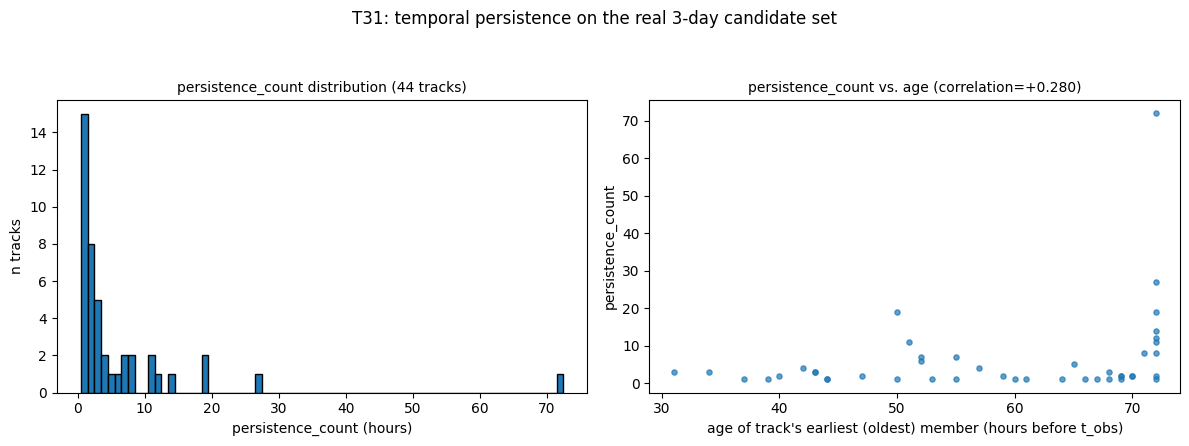

correlation(age, persistence_count) = +0.280 -- reported as a diagnostic, not corrected for (no age term exists in the tracking algorithm itself)


In [5]:
counts = np.array([t.persistence_count for t in tracks])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(counts, bins=np.arange(1, counts.max() + 2) - 0.5, edgecolor="black")
axes[0].set_xlabel("persistence_count (hours)"); axes[0].set_ylabel("n tracks")
axes[0].set_title(f"persistence_count distribution ({len(tracks)} tracks)", fontsize=10)

durations = np.array([t.persistence_duration_hours for t in tracks])
ages_of_earliest = np.array([float((RUN_T_OBS - t.earliest_t_s) / np.timedelta64(1, "h")) for t in tracks])
sc = axes[1].scatter(ages_of_earliest, counts, s=14, alpha=0.7)
axes[1].set_xlabel("age of track's earliest (oldest) member (hours before t_obs)")
axes[1].set_ylabel("persistence_count")
corr = float(np.corrcoef(ages_of_earliest, counts)[0, 1])
axes[1].set_title(f"persistence_count vs. age (correlation={corr:+.3f})", fontsize=10)

fig.suptitle("T31: temporal persistence on the real 3-day candidate set", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T31_persistence_tracks.png"), dpi=100)
plt.show()
print(f"correlation(age, persistence_count) = {corr:+.3f} -- reported as a diagnostic, not corrected for (no age term exists in the tracking algorithm itself)")

## 5. Visualize the longest real track's trajectory

longest real track: track0000, persistence_count=72, duration=71.0h, continuity=1.000


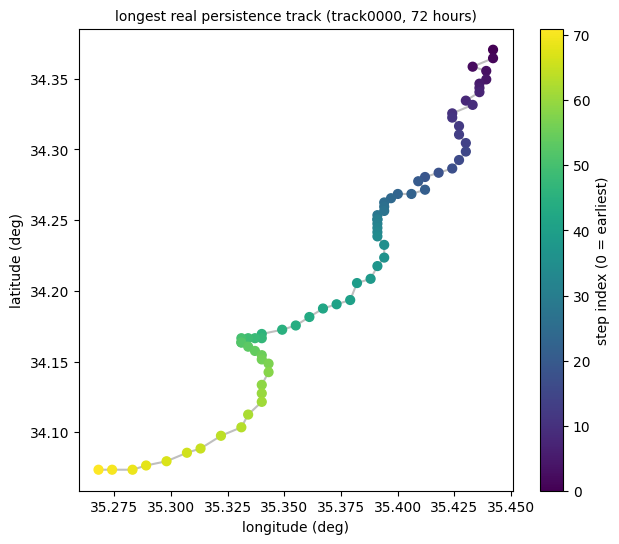

In [6]:
longest = max(tracks, key=lambda t: t.persistence_count)
print(f"longest real track: {longest.track_id}, persistence_count={longest.persistence_count}, "
      f"duration={longest.persistence_duration_hours}h, continuity={longest.temporal_continuity():.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(longest.lon_list, longest.lat_list, c=range(len(longest.lon_list)), cmap="viridis", s=40)
ax.plot(longest.lon_list, longest.lat_list, "-", color="gray", alpha=0.5, zorder=0)
fig.colorbar(sc, ax=ax, label="step index (0 = earliest)")
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title(f"longest real persistence track ({longest.track_id}, {longest.persistence_count} hours)", fontsize=10)
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T31_longest_track.png"), dpi=100)
plt.show()

## Known limitations (T31 scope only)

- `spatial_matching_radius_m`/`max_gap_hours` are documented PROTOTYPE/CONFIGURATION
  choices, not validated constants -- fully overridable.
- The tracker is a simple greedy nearest-neighbor assignment, not a claim of globally
  optimal multi-object tracking.
- Persistence alone does not rank/score candidates yet (T32-T39 not yet implemented);
  the `age`/`persistence_count` correlation plotted above is reported as a diagnostic
  only, per the standing instruction to carry such findings forward rather than
  suppress them.
- No Stage III module, and no existing T14-T17/T25/T26 module, was modified.

## 7. Requested review validation 1: empirical basis for `spatial_matching_radius_m`

**Not** derived from the ~48 km/72h total advection figure alone (per review request).
Instead: for every pair of ADJACENT real hourly timestamps (`t`, `t+1h`), compute the
distance from every candidate at `t` to its NEAREST candidate at `t+1h` -- the actual
single-hour nearest-neighbor displacement the tracker's own greedy matching step would
see, with no radius cutoff applied.

In [7]:
from iste.kdtree_neighborhood import project_to_local_metres

def _dist_m(lat1, lon1, lat2, lon2):
    x, y = project_to_local_metres(lat2, lon2, lat_ref=lat1, lon_ref=lon1)
    return float(np.sqrt(x[0] ** 2 + y[0] ** 2))

by_t_s = {}
for c in candidates:
    by_t_s.setdefault(c.t_s, []).append(c)
distinct_t_s = sorted(by_t_s.keys())

nn_displacements_m = []
n_adjacent_pairs_considered = 0
for i in range(len(distinct_t_s) - 1):
    t_a, t_b = distinct_t_s[i], distinct_t_s[i + 1]
    if (t_b - t_a) != np.timedelta64(1, "h"):
        continue  # only strictly adjacent (1h apart) timestamp pairs -- true 'consecutive'
    n_adjacent_pairs_considered += 1
    cands_b = by_t_s[t_b]
    for ca in by_t_s[t_a]:
        nearest = min(_dist_m(ca.y_peak, ca.x_peak, cb.y_peak, cb.x_peak) for cb in cands_b)
        nn_displacements_m.append(nearest)

nn_displacements_m = np.array(nn_displacements_m)
print(f"adjacent (1h-apart) timestamp pairs considered: {n_adjacent_pairs_considered}")
print(f"total candidate->nearest-next-hour-candidate displacement samples: {len(nn_displacements_m)}")

adjacent (1h-apart) timestamp pairs considered: 71
total candidate->nearest-next-hour-candidate displacement samples: 279


In [8]:
d_km = nn_displacements_m / 1000.0
print(f"median : {np.median(d_km):.3f} km")
print(f"mean   : {np.mean(d_km):.3f} km")
print(f"p90    : {np.percentile(d_km, 90):.3f} km")
print(f"p95    : {np.percentile(d_km, 95):.3f} km")
print(f"p99    : {np.percentile(d_km, 99):.3f} km")
print(f"max    : {np.max(d_km):.3f} km")
print()
for threshold_km in [0.5, 1.0, 2.0, 3.0]:
    frac = float(np.mean(d_km < threshold_km))
    print(f"fraction below {threshold_km:.1f} km: {frac:.3f}")

median : 0.667 km
mean   : 1.258 km
p90    : 3.616 km
p95    : 4.690 km
p99    : 7.791 km
max    : 9.656 km

fraction below 0.5 km: 0.315
fraction below 1.0 km: 0.677
fraction below 2.0 km: 0.835
fraction below 3.0 km: 0.878


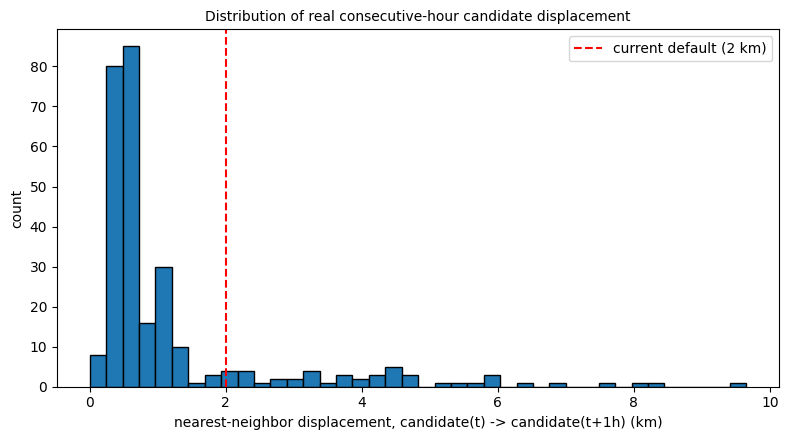

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(d_km, bins=40, edgecolor="black")
ax.axvline(2.0, color="red", linestyle="--", label="current default (2 km)")
ax.set_xlabel("nearest-neighbor displacement, candidate(t) -> candidate(t+1h) (km)")
ax.set_ylabel("count")
ax.set_title("Distribution of real consecutive-hour candidate displacement", fontsize=10)
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T31_displacement_distribution.png"), dpi=100)
plt.show()

## 8. Requested review validation: sensitivity to `spatial_matching_radius_m`

Re-run the (unmodified) tracker at 1 km, 2 km, and 3 km.

In [10]:
def _duration_buckets(tr_list):
    durs = np.array([t.persistence_duration_hours for t in tr_list])
    return {
        "n_tracks": len(tr_list),
        "longest_duration_h": float(durs.max()) if len(durs) else float("nan"),
        "n_ge_6h": int(np.sum(durs >= 6)),
        "n_ge_12h": int(np.sum(durs >= 12)),
        "n_ge_24h": int(np.sum(durs >= 24)),
        "n_ge_48h": int(np.sum(durs >= 48)),
        "mean_duration_h": float(durs.mean()) if len(durs) else float("nan"),
    }

sensitivity_rows = []
for radius_m in [1000.0, 2000.0, 3000.0]:
    tr = track_candidate_persistence(candidates, spatial_matching_radius_m=radius_m)
    stats = _duration_buckets(tr)
    stats["radius_km"] = radius_m / 1000.0
    sensitivity_rows.append(stats)

header = f"{'radius_km':>10s} {'n_tracks':>9s} {'longest_h':>10s} {'n>=6h':>7s} {'n>=12h':>7s} {'n>=24h':>7s} {'n>=48h':>7s} {'mean_h':>8s}"
print(header); print("-" * len(header))
for s in sensitivity_rows:
    print(f"{s['radius_km']:>10.1f} {s['n_tracks']:>9d} {s['longest_duration_h']:>10.1f} "
          f"{s['n_ge_6h']:>7d} {s['n_ge_12h']:>7d} {s['n_ge_24h']:>7d} {s['n_ge_48h']:>7d} {s['mean_duration_h']:>8.2f}")

 radius_km  n_tracks  longest_h   n>=6h  n>=12h  n>=24h  n>=48h   mean_h
------------------------------------------------------------------------
       1.0        88       25.0      11       2       1       0     2.22
       2.0        44       71.0      12       6       2       1     5.55
       3.0        38       71.0      13       6       2       1     6.66


## 9. Requested review validation 2: deep-dive on the longest track (`track0000`, default 2 km)

Determines whether `track0000` is a genuine continuously-moving candidate trajectory or
could be a greedy nearest-neighbor chain stitched between unrelated nearby candidates.

In [11]:
print(f"{longest.track_id}: persistence_count={longest.persistence_count}, "
      f"duration={longest.persistence_duration_hours}h, continuity={longest.temporal_continuity():.4f}")
print()

step_distances_m = []
gap_steps = []
for i in range(1, len(longest.t_s_list)):
    t_prev, t_curr = longest.t_s_list[i - 1], longest.t_s_list[i]
    lat_prev, lon_prev = longest.lat_list[i - 1], longest.lon_list[i - 1]
    lat_curr, lon_curr = longest.lat_list[i], longest.lon_list[i]
    d = _dist_m(lat_prev, lon_prev, lat_curr, lon_curr)
    step_distances_m.append(d)
    real_gap_h = float((t_curr - t_prev) / np.timedelta64(1, "h"))
    if real_gap_h > 1.0:
        gap_steps.append((t_prev, t_curr, real_gap_h, d))

step_distances_m = np.array(step_distances_m)
print(f"n consecutive-member steps: {len(step_distances_m)}")
print(f"max match distance  : {step_distances_m.max():.1f} m")
print(f"mean match distance : {step_distances_m.mean():.1f} m")
print(f"p95 match distance  : {np.percentile(step_distances_m, 95):.1f} m")
print(f"total displacement (sum of step distances, i.e. path length): {step_distances_m.sum() / 1000:.2f} km")
print()
print(f"steps using the max_gap_hours allowance (real gap > 1h): {len(gap_steps)}")
for t_prev, t_curr, real_gap_h, d in gap_steps:
    print(f"  bridged: {t_prev} -> {t_curr}  (gap={real_gap_h}h, match_distance={d:.1f} m)")

track0000: persistence_count=72, duration=71.0h, continuity=1.0000

n consecutive-member steps: 71
max match distance  : 1362.6 m
mean match distance : 621.8 m
p95 match distance  : 1063.9 m
total displacement (sum of step distances, i.e. path length): 44.15 km

steps using the max_gap_hours allowance (real gap > 1h): 0


In [12]:
print(f"{'step':>5s} {'t_s':>21s} {'lat':>9s} {'lon':>9s} {'step_dist_m':>12s} {'support':>10s}")
for i in range(len(longest.t_s_list)):
    d_str = f"{step_distances_m[i-1]:>12.1f}" if i > 0 else f"{'--':>12s}"
    print(f"{i:>5d} {str(longest.t_s_list[i]):>21s} {longest.lat_list[i]:>9.5f} {longest.lon_list[i]:>9.5f} "
          f"{d_str} {longest.support_scores[i]:>10.2f}")

 step                   t_s       lat       lon  step_dist_m    support
    0 2019-10-11T23:00:00.000000000  34.37055  35.44208           --     855.31
    1 2019-10-12T00:00:00.000000000  34.36455  35.44208        667.2     861.42
    2 2019-10-12T01:00:00.000000000  34.35855  35.43308       1061.9     875.98
    3 2019-10-12T02:00:00.000000000  34.35555  35.43908        643.9     875.08
    4 2019-10-12T03:00:00.000000000  34.34955  35.43908        667.2     872.27
    5 2019-10-12T04:00:00.000000000  34.34655  35.43608        432.6     929.98
    6 2019-10-12T05:00:00.000000000  34.34355  35.43608        333.6     942.20
    7 2019-10-12T06:00:00.000000000  34.34055  35.43608        333.6     965.81
    8 2019-10-12T07:00:00.000000000  34.33455  35.43008        865.2     982.22
    9 2019-10-12T08:00:00.000000000  34.33155  35.43308        432.6     996.77
   10 2019-10-12T09:00:00.000000000  34.32555  35.42408       1062.1    1015.16
   11 2019-10-12T10:00:00.000000000  34.32255  3

### Plot: longest track with per-step match distances annotated

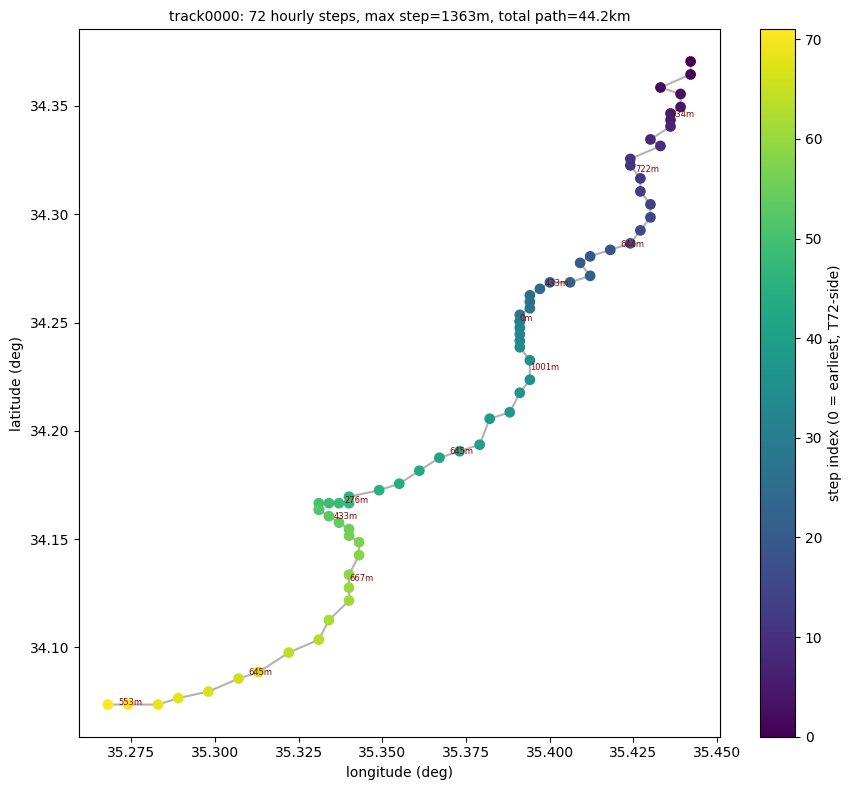

In [13]:
fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(longest.lon_list, longest.lat_list, c=range(len(longest.lon_list)), cmap="viridis", s=45, zorder=3)
ax.plot(longest.lon_list, longest.lat_list, "-", color="gray", alpha=0.6, zorder=1)
fig.colorbar(sc, ax=ax, label="step index (0 = earliest, T72-side)")

# annotate every 6th step's match distance to avoid overcrowding
for i in range(1, len(longest.lon_list)):
    if i % 6 == 0 or i == len(longest.lon_list) - 1:
        mx = (longest.lon_list[i - 1] + longest.lon_list[i]) / 2
        my = (longest.lat_list[i - 1] + longest.lat_list[i]) / 2
        ax.annotate(f"{step_distances_m[i-1]:.0f}m", (mx, my), fontsize=6, color="darkred")

ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title(f"{longest.track_id}: {longest.persistence_count} hourly steps, "
             f"max step={step_distances_m.max():.0f}m, total path={step_distances_m.sum()/1000:.1f}km", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T31_longest_track_annotated.png"), dpi=110)
plt.show()

## Review validation summary

This section (7-9) was added in response to a review request and does not change
`iste/phase3_persistence.py` -- the tracking algorithm is unmodified. Results above
should be read together to judge whether the default `spatial_matching_radius_m=2000.0`
is empirically reasonable and whether `track0000` represents a genuine continuously
moving feature.